# Five-Household Energy Trading Game with Battery Storage and Dynamic Pricing

This notebook simulates a **5-player stochastic game-theoretic peer-to-peer (P2P) energy trading market** over a full 24-hour cycle using real Australian household demand and rooftop solar generation data.

## Key System Features
1. **Battery Energy Storage Systems (BESS)**: Each of the 5 households is equipped with a residential battery (5.0 kWh capacity, 2.5 kW charge/discharge power limit, 95% efficiency, 10%–90% SOC limits).
2. **State-of-Charge Continuity**: Hourly battery charge and discharge actions transition the state-of-charge (SOC) sequentially across all 24 hours.
3. **Dynamic P2P Demand-Responsive Pricing**: Rather than assuming a constant trading price, the P2P price responds to the active trading pool's demand pressure ($P_{P2P} = f(\text{Deficit} / \text{Surplus})$).
4. **Game-Theoretic Equilibrium & Best Response**: For each hour, we identify the pure-strategy Nash Equilibrium and the exact best response for every household in dictionary format (`{player_id: best_action}`).
5. **Quantified Household & Community Benefits**: Total cost savings and community welfare gain are analyzed with numeric tables and publication-grade plots.

In [2]:
# ── Setup: ensure project root is on the path ──────────────────────────────
%load_ext autoreload
%autoreload 2

import sys, os

# Determine project root whether run from notebook/ or repo root
if os.path.exists('data'):
    PROJECT_ROOT = os.path.abspath('.')
elif os.path.exists('../data'):
    PROJECT_ROOT = os.path.abspath('..')
else:
    PROJECT_ROOT = os.path.abspath(os.path.join(os.getcwd(), '..'))

if PROJECT_ROOT not in sys.path:
    sys.path.insert(0, PROJECT_ROOT)

import warnings
warnings.filterwarnings('ignore')

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.ticker as mticker
import matplotlib.patches as mpatches
import seaborn as sns

# Ensure results directory exists
fig_dir = os.path.join(PROJECT_ROOT, 'results', 'figures')
os.makedirs(fig_dir, exist_ok=True)

# Clean plotting style
plt.rcParams.update({
    'figure.dpi': 120,
    'font.size': 11,
    'axes.titlesize': 13,
    'axes.labelsize': 11,
    'legend.fontsize': 9,
})

print('Environment and figure directory ready.')
print(f'Project root: {PROJECT_ROOT}')


The autoreload extension is already loaded. To reload it, use:
  %reload_ext autoreload
Environment and figure directory ready.
Project root: e:\Stochastic-Game-Theoretic-Optimization-under-uncertain-energy-conditions


## 1. Load Demand & Solar Data

In [3]:
# ── Load demand and customer mapping ──────────────────────────────────────
DATA_PATH    = os.path.join(PROJECT_ROOT, 'data', 'processed', 'five_house_hourly_demand.csv')
MAPPING_PATH = os.path.join(PROJECT_ROOT, 'data', 'processed', 'customer_id_mapping.csv')

df_raw = pd.read_csv(DATA_PATH, parse_dates=['timestamp'])
df_map = pd.read_csv(MAPPING_PATH)

print(f'Raw dataset: {df_raw.shape[0]} rows, {df_raw.shape[1]} columns')
print('Customer Mapping Table:')
display(df_map)

Raw dataset: 43800 rows, 9 columns
Customer Mapping Table:


,house_id,source_customer_id,postcode,generator_capacity_kwp,selection_criteria
0,H001,1,2076,3.78,"365 complete actual days for GC, CL, and GG"
1,H002,3,2263,1.00,"365 complete actual days for GC, CL, and GG"
2,H003,4,2220,1.00,"365 complete actual days for GC, CL, and GG"
3,H004,6,2230,2.00,"365 complete actual days for GC, CL, and GG"
4,H005,7,2259,2.16,"365 complete actual days for GC, CL, and GG"


In [4]:
# ── Filter 1 Day (2012-07-01) for the 5 Households ─────────────────────────
SIM_DATE   = pd.Timestamp('2012-07-01')
PLAYER_IDS = ['H001', 'H002', 'H003', 'H004', 'H005']

df_day = df_raw[
    (df_raw['timestamp'].dt.date == SIM_DATE.date()) &
    (df_raw['house_id'].isin(PLAYER_IDS))
].copy()

# Pivot hourly values: index=hour (0-23), columns=house_id
df_demand = df_day.pivot(index='timestamp', columns='house_id', values='total_demand_kwh').sort_index()
df_solar  = df_day.pivot(index='timestamp', columns='house_id', values='solar_kwh').sort_index()

# Raw surplus and deficit before battery action
df_net_raw = df_solar - df_demand
df_surplus_raw = df_net_raw.clip(lower=0)
df_deficit_raw = (-df_net_raw).clip(lower=0)

print(f'Simulation Date: {SIM_DATE.date()} (24 hourly intervals)')
print('\nTotal 24h Demand per Household (kWh):')
display(df_demand.sum().rename('Total Demand (kWh)'))
print('\nTotal 24h Solar Generation per Household (kWh):')
display(df_solar.sum().rename('Total Solar (kWh)'))

Simulation Date: 2012-07-01 (24 hourly intervals)

Total 24h Demand per Household (kWh):


house_id
H001    22.796
H002    14.626
H003    19.687
H004    46.629
H005    16.043
Name: Total Demand (kWh), dtype: float64


Total 24h Solar Generation per Household (kWh):


house_id
H001    8.726
H002    1.795
H003    2.509
H004    3.288
H005    4.189
Name: Total Solar (kWh), dtype: float64

## 2. Battery Storage & Dynamic Pricing Configuration

In [5]:
# ── Initialize BESS for all households & pricing model ─────────────────────
import importlib
from src.energy.battery import BatteryStorage
from src.game.pricing import DynamicPricingModel, ElasticDemandPricing, MidMarketPricing

# Defensive reload for active Jupyter kernels
try:
    import src.game.game
    importlib.reload(src.game.game)
    from src.game.game import run_n_player_game, create_default_batteries, NPlayerGameResult
except (ImportError, AttributeError):
    try:
        from src.energy.battery import create_default_batteries
        from src.game.game import run_n_player_game, NPlayerGameResult
    except (ImportError, AttributeError):
        from src.game.game import run_n_player_game, NPlayerGameResult
        def create_default_batteries(player_ids, capacity_kwh=5.0, initial_soc=0.50, **kwargs):
            return {pid: BatteryStorage(capacity_kwh=capacity_kwh, initial_soc=initial_soc, **kwargs) for pid in player_ids}

# Battery specifications for all 5 houses
BATTERY_CAPACITY_KWH = 5.0
INITIAL_SOC          = 0.50
MIN_SOC              = 0.10
MAX_SOC              = 0.90
MAX_POWER_KW         = 2.50
EFFICIENCY           = 0.95

# Grid tariff parameters (AUD/kWh)
GRID_IMPORT_PRICE  = 0.30
GRID_EXPORT_CREDIT = 0.08

# Instantiate independent batteries for H001-H005
batteries = create_default_batteries(
    player_ids=PLAYER_IDS,
    capacity_kwh=BATTERY_CAPACITY_KWH,
    max_charge_rate_kw=MAX_POWER_KW,
    max_discharge_rate_kw=MAX_POWER_KW,
    charge_efficiency=EFFICIENCY,
    discharge_efficiency=EFFICIENCY,
    min_soc=MIN_SOC,
    max_soc=MAX_SOC,
    initial_soc=INITIAL_SOC,
)

# Demand-responsive Dynamic Pricing Model
pricing_model = DynamicPricingModel(max_pressure=2.0, sensitivity=1.0)

print('Batteries initialized for all 5 households:')
for pid, b in batteries.items():
    print(f'  {pid}: Capacity={b.capacity_kwh} kWh, Initial SOC={b.soc*100:.0f}%, Max Power={b.max_charge_rate_kw} kW')
print(f'\nPricing Model: {pricing_model.name()}')
print(f'Tariff bounds: FIT=${GRID_EXPORT_CREDIT:.2f}/kWh, Retail=${GRID_IMPORT_PRICE:.2f}/kWh')


Batteries initialized for all 5 households:
  H001: Capacity=5.0 kWh, Initial SOC=50%, Max Power=2.5 kW
  H002: Capacity=5.0 kWh, Initial SOC=50%, Max Power=2.5 kW
  H003: Capacity=5.0 kWh, Initial SOC=50%, Max Power=2.5 kW
  H004: Capacity=5.0 kWh, Initial SOC=50%, Max Power=2.5 kW
  H005: Capacity=5.0 kWh, Initial SOC=50%, Max Power=2.5 kW

Pricing Model: DynamicPricingModel(max_p=2.0, sens=1.0)
Tariff bounds: FIT=$0.08/kWh, Retail=$0.30/kWh


## 3. Run Sequential 24-Hour Game Simulation with Batteries

In [7]:
# ── Execute 24 hourly rounds with state transitions ────────────────────────
hourly_results: list[NPlayerGameResult] = []

for ts, row_surplus in df_surplus_raw.iterrows():
    row_deficit = df_deficit_raw.loc[ts]
    
    surpluses = [float(row_surplus[pid]) for pid in PLAYER_IDS]
    deficits  = [float(row_deficit[pid])  for pid in PLAYER_IDS]
    
    # Pass the batteries directly: they are dispatched pre-game and their SOC updates in place!
    result = run_n_player_game(
        player_ids=PLAYER_IDS,
        surpluses_kwh=surpluses,
        deficits_kwh=deficits,
        grid_import_price_aud=GRID_IMPORT_PRICE,
        grid_export_credit_aud=GRID_EXPORT_CREDIT,
        pricing_model = pricing_model,
        batteries=batteries,
        timestamp=ts,
    )
    hourly_results.append(result)

print(f'Successfully simulated {len(hourly_results)} consecutive hours.')
ne_count = sum(1 for r in hourly_results if r.has_equilibrium)
print(f'Nash Equilibria discovered: {ne_count}/24 hours.')

Successfully simulated 24 consecutive hours.
Nash Equilibria discovered: 24/24 hours.


## 4. Best Response & Hourly Operation Table

In [19]:
# ── Construct detailed hourly best-response and battery log ────────────────
records = []
for r in hourly_results:
    hour = r.timestamp.hour
    eq = r.equilibrium_result.selected_equilibrium if r.equilibrium_result else None
    
    for pid in PLAYER_IDS:
        raw_s = r.raw_surpluses_kwh.get(pid, 0.0)
        raw_d = r.raw_deficits_kwh.get(pid, 0.0)
        ch = r.battery_charged_kwh.get(pid, 0.0)
        dis = r.battery_discharged_kwh.get(pid, 0.0)
        soc = r.battery_final_soc.get(pid, 0.0)
        net_s = r.surpluses_kwh.get(pid, 0.0)
        net_d = r.deficits_kwh.get(pid, 0.0)
        action = r.selected_actions.get(pid, 'N/A')
        
        role = 'SELLER' if net_s > 0.001 else ('BUYER' if net_d > 0.001 else 'SELF_SUFFICIENT')
        
        u_game = eq.utilities.get(pid, 0.0) if eq else 0.0
        u_base = r.equilibrium_result.baseline_utilities.get(pid, 0.0) if r.equilibrium_result else 0.0
        save = r.savings_aud.get(pid, 0.0)
        
        records.append({
            'Hour': hour,
            'Player': pid,
            'Raw_Surplus_kWh': round(raw_s, 3),
            'Raw_Deficit_kWh': round(raw_d, 3),
            'Batt_Charged_kWh': round(ch, 3),
            'Batt_Discharged_kWh': round(dis, 3),
            'Batt_SOC': round(soc, 3),
            'Net_Surplus_kWh': round(net_s, 3),
            'Net_Deficit_kWh': round(net_d, 3),
            'P2P_Price_AUD': round(r.equilibrium_p2p_price_aud or r.p2p_price_aud, 4),
            'Role': role,
            'Best_Response': action,
            'Saving_AUD': round(save, 4),
        })

df_ops = pd.DataFrame(records)
print(f'Full Operation Log ({df_ops.shape[0]} rows):')
display(df_ops.head(25))

Full Operation Log (120 rows):


,Hour,Player,Raw_Surplus_kWh,Raw_Deficit_kWh,Batt_Charged_kWh,Batt_Discharged_kWh,Batt_SOC,Net_Surplus_kWh,Net_Deficit_kWh,P2P_Price_AUD,Role,Best_Response,Saving_AUD
0,0,H001,0.0,4.141,0.0,0.0,0.1,0.0,4.141,0.19,BUYER,TRADE,0.0
1,0,H002,0.0,1.892,0.0,0.0,0.1,0.0,1.892,0.19,BUYER,TRADE,0.0
2,0,H003,0.0,0.168,0.0,0.0,0.1,0.0,0.168,0.19,BUYER,TRADE,0.0
3,0,H004,0.0,5.548,0.0,0.0,0.1,0.0,5.548,0.19,BUYER,TRADE,0.0
4,0,H005,0.0,1.396,0.0,0.0,0.1,0.0,1.396,0.19,BUYER,TRADE,0.0
5,1,H001,0.0,3.661,0.0,0.0,0.1,0.0,3.661,0.19,BUYER,TRADE,0.0
6,1,H002,0.0,1.419,0.0,0.0,0.1,0.0,1.419,0.19,BUYER,TRADE,0.0
7,1,H003,0.0,4.074,0.0,0.0,0.1,0.0,4.074,0.19,BUYER,TRADE,0.0
8,1,H004,0.0,5.382,0.0,0.0,0.1,0.0,5.382,0.19,BUYER,TRADE,0.0
9,1,H005,0.0,0.153,0.0,0.0,0.1,0.0,0.153,0.19,BUYER,TRADE,0.0


In [11]:
# ── Best Response Dict per Household for each hour ─────────────────────────
print('Best Response Matrix (Player Action per Hour):')
df_br_pivot = df_ops.pivot(index='Hour', columns='Player', values='Best_Response')
display(df_br_pivot)

print('\nBest Response as Python dictionary for Hour 12 (peak solar):')
h12_dict = df_ops[df_ops['Hour'] == 12].set_index('Player')['Best_Response'].to_dict()
print(h12_dict)

# ── Detailed Hourly Buying Price & Counterparty Breakdown ─────────────────
trade_records = []
for h, res in enumerate(hourly_results):
    p2p_price = res.equilibrium_p2p_price_aud or res.p2p_price_aud
    surpluses = res.surpluses_kwh
    deficits = res.deficits_kwh
    actions = res.selected_actions
    
    sellers = {pid: s for pid, s in surpluses.items() if actions.get(pid) == 'TRADE' and s > 1e-4}
    buyers = {pid: d for pid, d in deficits.items() if actions.get(pid) == 'TRADE' and d > 1e-4}
    
    tot_s = sum(sellers.values())
    tot_d = sum(buyers.values())
    q_traded = min(tot_s, tot_d)
    
    for pid in PLAYER_IDS:
        action = actions.get(pid, 'TRADE')
        net_s = surpluses.get(pid, 0.0)
        net_d = deficits.get(pid, 0.0)
        
        if net_s > 1e-4:
            sold_p2p = (net_s / tot_s) * q_traded if tot_s > 0 else 0.0
            sold_grid = net_s - sold_p2p
            who_bought = []
            for b_pid, b_val in buyers.items():
                b_share = (b_val / tot_d) * sold_p2p if tot_d > 0 else 0.0
                if b_share > 1e-4:
                    who_bought.append(f"{b_share:.3f} kWh to {b_pid} @ ${p2p_price:.4f}")
            if sold_grid > 1e-4:
                who_bought.append(f"{sold_grid:.3f} kWh to Grid @ ${GRID_EXPORT_CREDIT:.2f}")
            trade_records.append({
                'Hour': h,
                'Player': pid,
                'Best_Response': action,
                'Role': 'SELLER',
                'Net_Deficit_kWh': 0.0,
                'P2P_Bought_kWh': 0.0,
                'Grid_Bought_kWh': 0.0,
                'Buy_Price_AUD': None,
                'Counterparty_Details': f"Sold: {', '.join(who_bought)}",
            })
        elif net_d > 1e-4:
            bought_p2p = (net_d / tot_d) * q_traded if tot_d > 0 else 0.0
            bought_grid = net_d - bought_p2p
            from_whom = []
            if bought_p2p > 1e-4:
                for s_pid, s_val in sellers.items():
                    s_share = (s_val / tot_s) * bought_p2p
                    from_whom.append(f"{s_share:.3f} kWh from {s_pid} @ ${p2p_price:.4f}")
            if bought_grid > 1e-4:
                from_whom.append(f"{bought_grid:.3f} kWh from Main Grid @ ${GRID_IMPORT_PRICE:.2f}")
            
            effective_price = (bought_p2p * p2p_price + bought_grid * GRID_IMPORT_PRICE) / net_d if net_d > 0 else GRID_IMPORT_PRICE
            price_display = f"${p2p_price:.4f} (P2P)" if bought_grid <= 1e-4 else (f"${GRID_IMPORT_PRICE:.2f} (Grid)" if bought_p2p <= 1e-4 else f"${effective_price:.4f} (Avg: P2P+Grid)")
            
            trade_records.append({
                'Hour': h,
                'Player': pid,
                'Best_Response': action,
                'Role': 'BUYER',
                'Net_Deficit_kWh': round(net_d, 3),
                'P2P_Bought_kWh': round(bought_p2p, 3),
                'Grid_Bought_kWh': round(bought_grid, 3),
                'Buy_Price_AUD': price_display,
                'Counterparty_Details': f"Bought: {', '.join(from_whom)}",
            })
        else:
            trade_records.append({
                'Hour': h,
                'Player': pid,
                'Best_Response': action,
                'Role': 'SELF_SUFFICIENT',
                'Net_Deficit_kWh': 0.0,
                'P2P_Bought_kWh': 0.0,
                'Grid_Bought_kWh': 0.0,
                'Buy_Price_AUD': 'N/A',
                'Counterparty_Details': 'Self-Sufficient (Demand covered by local solar + battery)',
            })

df_trade = pd.DataFrame(trade_records)

print('\n' + '=' * 80)
print('  HOURLY TRADING, BUYING PRICE & COUNTERPARTY BREAKDOWN (ALL 24 HOURS)')
print('=' * 80)
# Display non-self-sufficient or full table
display(df_trade.head(30))

print('\n--- Summary of Active P2P Peer Trades (Hours 14:00 - 15:00) ---')
display(df_trade[df_trade['Role'].isin(['BUYER', 'SELLER']) & (df_trade['Hour'].isin([14, 15]))][['Hour', 'Player', 'Best_Response', 'Role', 'Buy_Price_AUD', 'Counterparty_Details']])


Best Response Matrix (Player Action per Hour):


Player,H001,H002,H003,H004,H005
Hour,,,,,
0,TRADE,TRADE,TRADE,TRADE,TRADE
1,TRADE,TRADE,TRADE,TRADE,TRADE
2,TRADE,TRADE,TRADE,TRADE,TRADE
3,TRADE,TRADE,TRADE,TRADE,TRADE
4,TRADE,TRADE,TRADE,TRADE,TRADE
5,TRADE,TRADE,TRADE,TRADE,TRADE
6,TRADE,TRADE,TRADE,TRADE,TRADE
7,TRADE,TRADE,TRADE,TRADE,TRADE
8,TRADE,TRADE,TRADE,TRADE,TRADE



Best Response as Python dictionary for Hour 12 (peak solar):
{'H001': 'TRADE', 'H002': 'TRADE', 'H003': 'TRADE', 'H004': 'TRADE', 'H005': 'TRADE'}


## 5. Total Benefits Summary: Per Household & Community

In [12]:
# ── Aggregate 24h Totals for Households and Community ──────────────────────
summary_data = []
for pid in PLAYER_IDS:
    p_df = df_ops[df_ops['Player'] == pid]
    summary_data.append({
        'Household': pid,
        'Total_Demand_kWh': round(df_demand[pid].sum(), 2),
        'Total_Solar_kWh': round(df_solar[pid].sum(), 2),
        'Batt_Total_Charged_kWh': round(p_df['Batt_Charged_kWh'].sum(), 2),
        'Batt_Total_Discharged_kWh': round(p_df['Batt_Discharged_kWh'].sum(), 2),
        'Final_SOC': round(p_df.iloc[-1]['Batt_SOC'], 3),
        'Net_Surplus_P2P_kWh': round(p_df['Net_Surplus_kWh'].sum(), 2),
        'Net_Deficit_P2P_kWh': round(p_df['Net_Deficit_kWh'].sum(), 2),
        'Total_Saving_AUD': round(p_df['Saving_AUD'].sum(), 4),
        'Hours_as_Seller': int((p_df['Role'] == 'SELLER').sum()),
        'Hours_as_Buyer': int((p_df['Role'] == 'BUYER').sum()),
        'Hours_Self_Sufficient': int((p_df['Role'] == 'SELF_SUFFICIENT').sum()),
    })

df_summary = pd.DataFrame(summary_data)

# Community aggregation row
comm_savings = df_summary['Total_Saving_AUD'].sum()
comm_row = pd.DataFrame([{
    'Household': 'COMMUNITY_TOTAL',
    'Total_Demand_kWh': round(df_summary['Total_Demand_kWh'].sum(), 2),
    'Total_Solar_kWh': round(df_summary['Total_Solar_kWh'].sum(), 2),
    'Batt_Total_Charged_kWh': round(df_summary['Batt_Total_Charged_kWh'].sum(), 2),
    'Batt_Total_Discharged_kWh': round(df_summary['Batt_Total_Discharged_kWh'].sum(), 2),
    'Final_SOC': round(df_summary['Final_SOC'].mean(), 3),
    'Net_Surplus_P2P_kWh': round(df_summary['Net_Surplus_P2P_kWh'].sum(), 2),
    'Net_Deficit_P2P_kWh': round(df_summary['Net_Deficit_P2P_kWh'].sum(), 2),
    'Total_Saving_AUD': round(comm_savings, 4),
    'Hours_as_Seller': '-',
    'Hours_as_Buyer': '-',
    'Hours_Self_Sufficient': '-',
}])

df_summary_full = pd.concat([df_summary, comm_row], ignore_index=True)
print('=' * 80)
print('  DAILY 24-HOUR ENERGY & BENEFIT SUMMARY TABLE (WITH BATTERIES)')
print('=' * 80)
display(df_summary_full)
print(f'\nTotal Community Financial Saving: AUD ${comm_savings:.4f} over 24 hours.')

  DAILY 24-HOUR ENERGY & BENEFIT SUMMARY TABLE (WITH BATTERIES)


,Household,Total_Demand_kWh,Total_Solar_kWh,Batt_Total_Charged_kWh,Batt_Total_Discharged_kWh,Final_SOC,Net_Surplus_P2P_kWh,Net_Deficit_P2P_kWh,Total_Saving_AUD,Hours_as_Seller,Hours_as_Buyer,Hours_Self_Sufficient
0,H001,22.80,8.73,4.21,3.80,0.1,1.81,16.29,0.1482,2,11,11
1,H002,14.63,1.80,0.43,0.39,0.1,0.00,12.87,0.0144,0,19,5
2,H003,19.69,2.51,0.18,0.17,0.1,0.00,17.20,0.0220,0,22,2
3,H004,46.63,3.29,0.67,0.60,0.1,0.00,43.41,0.1068,0,22,2
4,H005,16.04,4.19,0.86,0.78,0.1,0.00,11.94,0.0000,0,18,6
5,COMMUNITY_TOTAL,119.79,20.52,6.35,5.74,0.1,1.81,101.71,0.2914,-,-,-



Total Community Financial Saving: AUD $0.2914 over 24 hours.


## 6. Comprehensive Visualisations

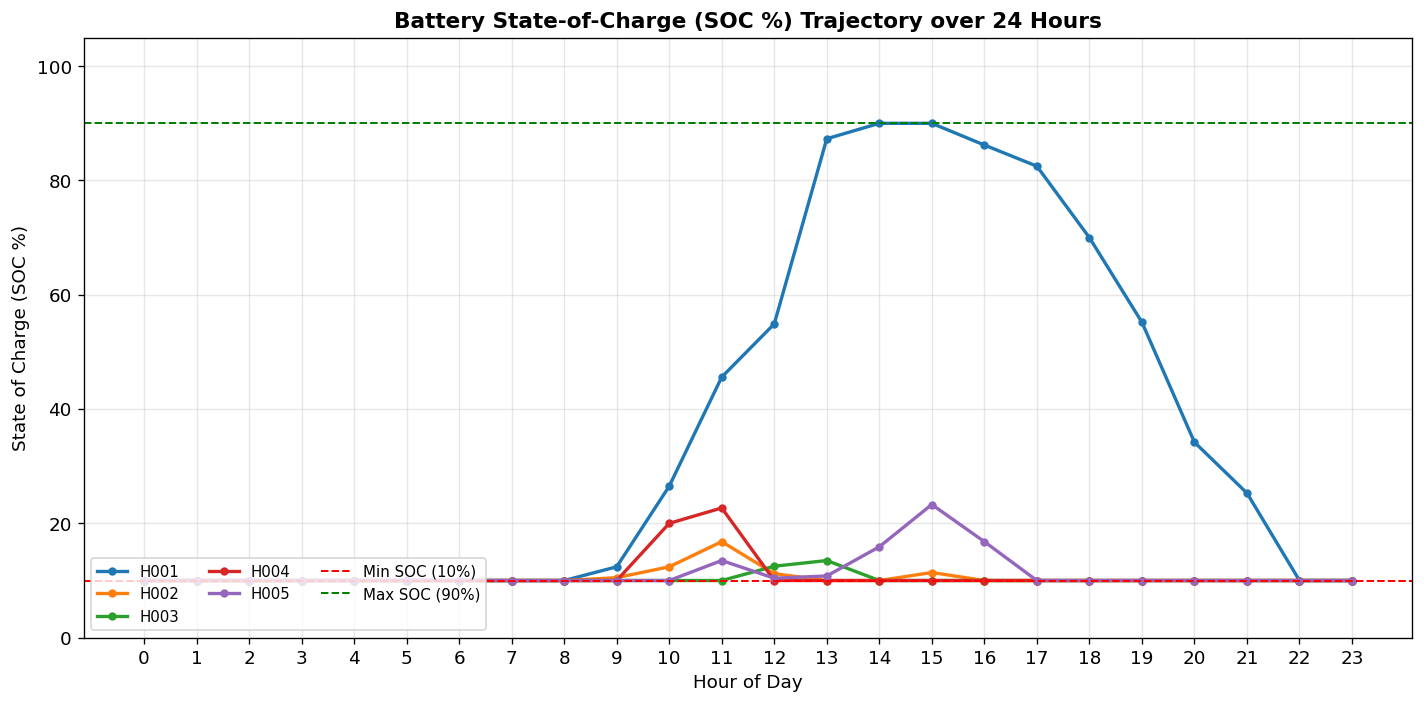

In [13]:
# ── PLOT 1: Hourly Battery State of Charge (SOC) Trajectories ──────────────
hours = list(range(24))
colors = ['#1f77b4', '#ff7f0e', '#2ca02c', '#d62728', '#9467bd']

df_soc = df_ops.pivot(index='Hour', columns='Player', values='Batt_SOC')

plt.figure(figsize=(12, 6))
for i, pid in enumerate(PLAYER_IDS):
    plt.plot(hours, df_soc[pid] * 100, marker='o', markersize=4, label=pid, color=colors[i], linewidth=2)

plt.axhline(MIN_SOC * 100, color='red', linestyle='--', linewidth=1.2, label=f'Min SOC ({MIN_SOC*100:.0f}%)')
plt.axhline(MAX_SOC * 100, color='green', linestyle='--', linewidth=1.2, label=f'Max SOC ({MAX_SOC*100:.0f}%)')
plt.title('Battery State-of-Charge (SOC %) Trajectory over 24 Hours', fontweight='bold')
plt.xlabel('Hour of Day')
plt.ylabel('State of Charge (SOC %)')
plt.xticks(hours)
plt.ylim(0, 105)
plt.grid(True, alpha=0.3)
plt.legend(loc='lower left', ncol=3)
plt.tight_layout()
plt.savefig(os.path.join(fig_dir, '05_battery_soc_trajectory.png'), bbox_inches='tight')
plt.show()

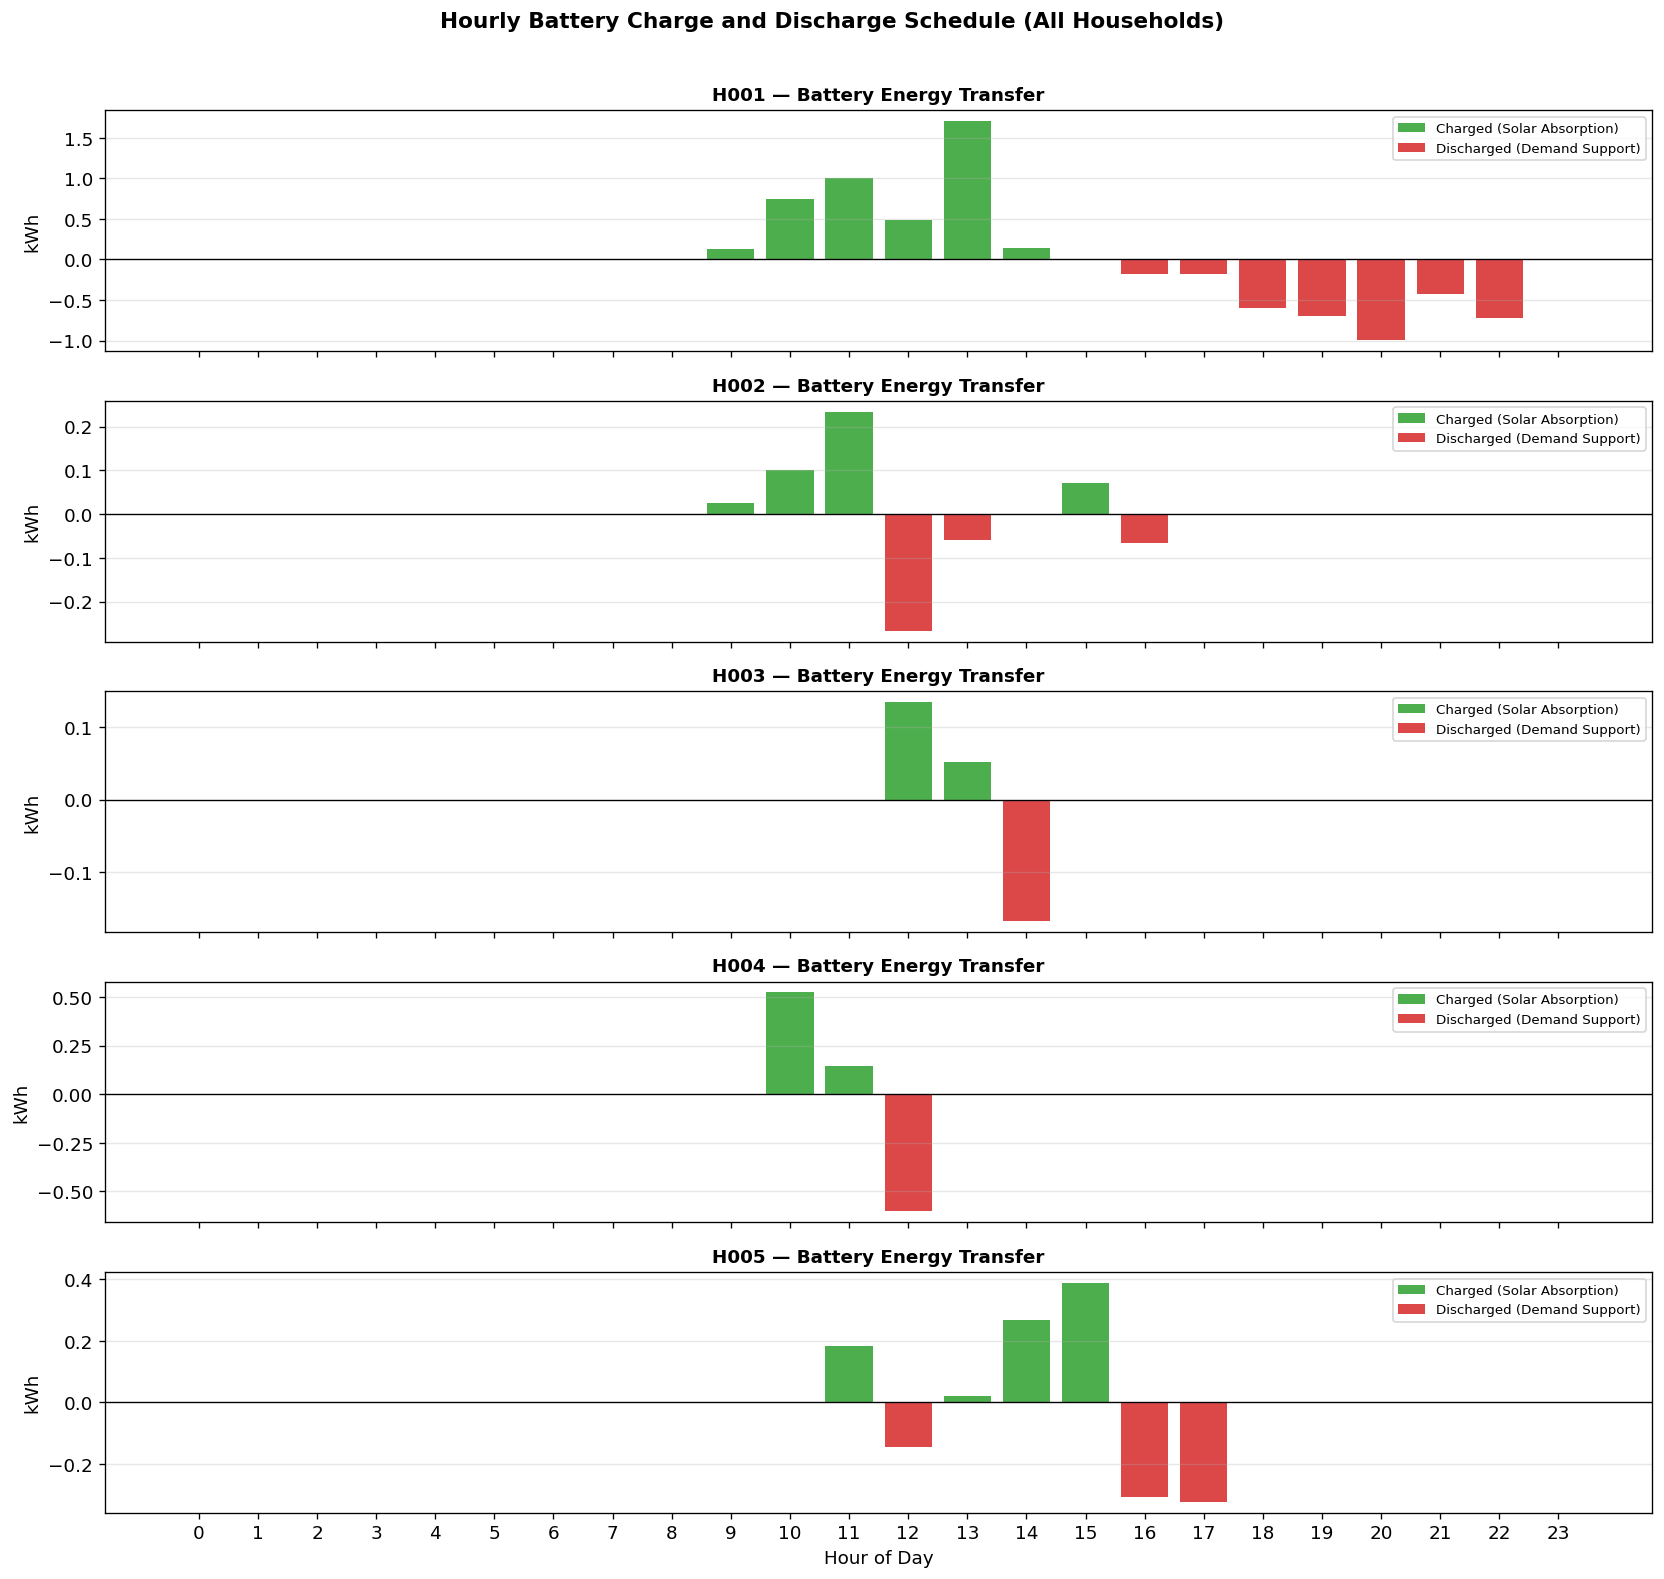

In [14]:
# ── PLOT 2: Battery Charging (+) & Discharging (-) Power ───────────────────
df_ch = df_ops.pivot(index='Hour', columns='Player', values='Batt_Charged_kWh')
df_dis = df_ops.pivot(index='Hour', columns='Player', values='Batt_Discharged_kWh')

fig, axes = plt.subplots(5, 1, figsize=(14, 13), sharex=True)
for i, pid in enumerate(PLAYER_IDS):
    axes[i].bar(hours, df_ch[pid], color='#2ca02c', alpha=0.85, label='Charged (Solar Absorption)')
    axes[i].bar(hours, -df_dis[pid], color='#d62728', alpha=0.85, label='Discharged (Demand Support)')
    axes[i].axhline(0, color='black', linewidth=0.8)
    axes[i].set_ylabel('kWh')
    axes[i].set_title(f'{pid} — Battery Energy Transfer', fontweight='bold', fontsize=11)
    axes[i].grid(True, alpha=0.3, axis='y')
    axes[i].legend(loc='upper right', fontsize=8)

axes[-1].set_xlabel('Hour of Day')
axes[-1].set_xticks(hours)
plt.suptitle('Hourly Battery Charge and Discharge Schedule (All Households)', y=1.01, fontweight='bold', fontsize=13)
plt.tight_layout()
plt.savefig(os.path.join(fig_dir, '05_battery_charge_discharge.png'), bbox_inches='tight')
plt.show()

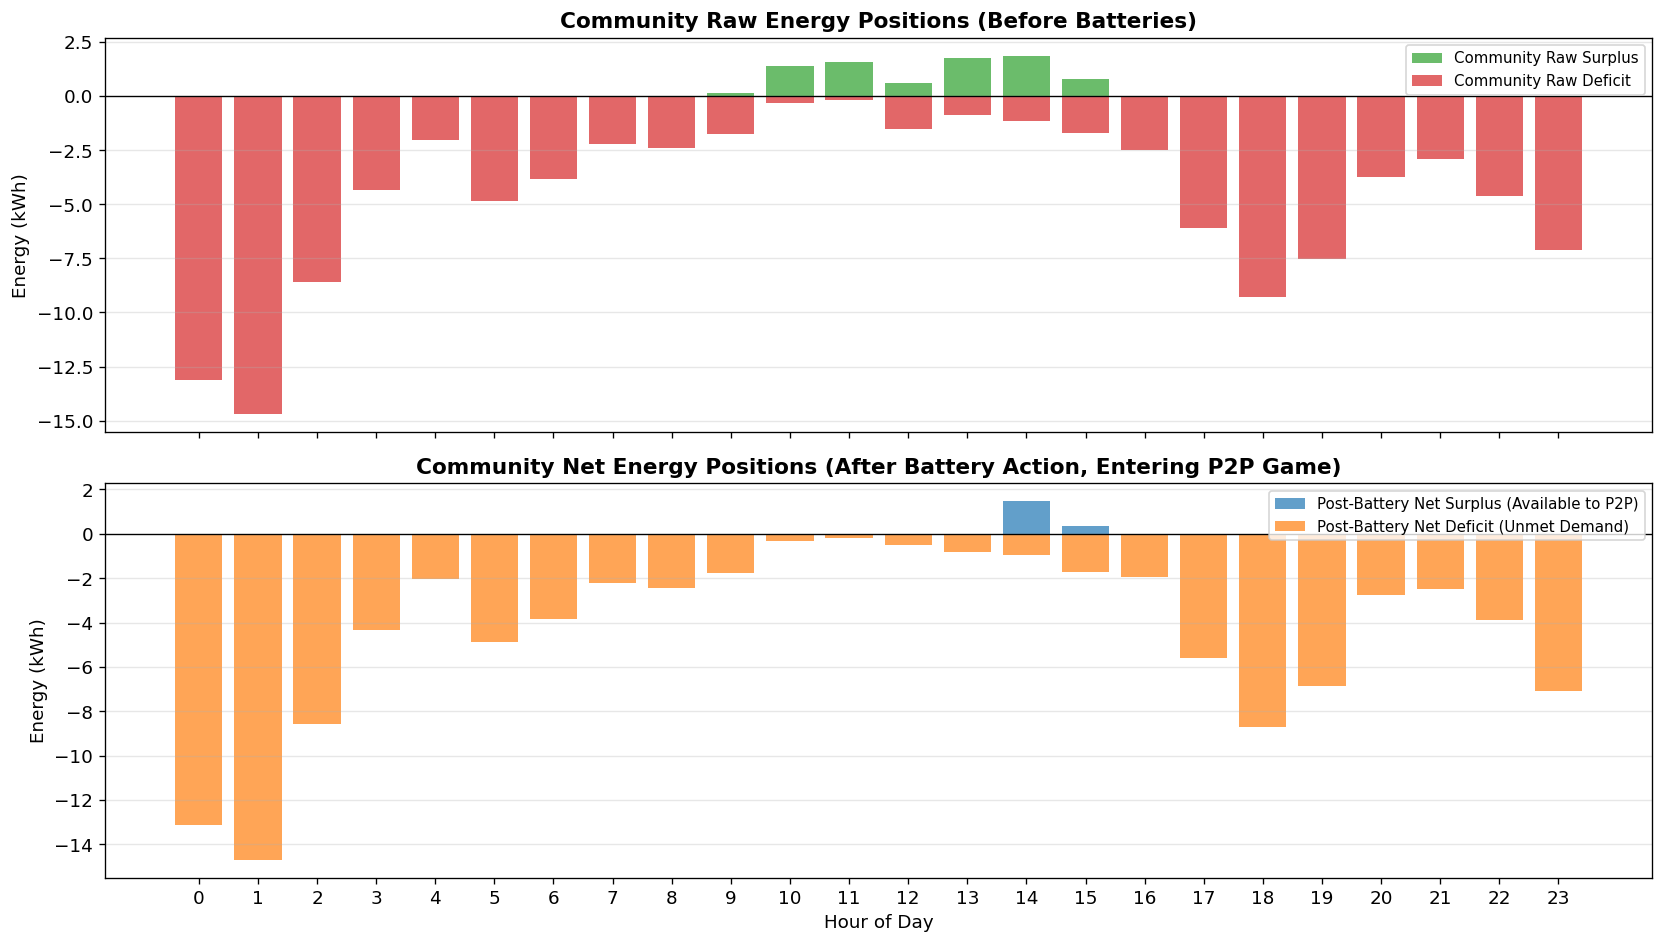

In [15]:
# ── PLOT 3: Raw vs. Post-Battery Net Energy Positions ──────────────────────
# Demonstrates how battery smoothing reduces spikes before entering P2P market
fig, axes = plt.subplots(2, 1, figsize=(14, 8), sharex=True)

total_raw_surplus = df_ops.groupby('Hour')['Raw_Surplus_kWh'].sum()
total_raw_deficit = df_ops.groupby('Hour')['Raw_Deficit_kWh'].sum()
total_net_surplus = df_ops.groupby('Hour')['Net_Surplus_kWh'].sum()
total_net_deficit = df_ops.groupby('Hour')['Net_Deficit_kWh'].sum()

axes[0].bar(hours, total_raw_surplus, color='#2ca02c', alpha=0.7, label='Community Raw Surplus')
axes[0].bar(hours, -total_raw_deficit, color='#d62728', alpha=0.7, label='Community Raw Deficit')
axes[0].axhline(0, color='black', linewidth=0.8)
axes[0].set_title('Community Raw Energy Positions (Before Batteries)', fontweight='bold')
axes[0].set_ylabel('Energy (kWh)')
axes[0].legend(loc='upper right')
axes[0].grid(True, alpha=0.3, axis='y')

axes[1].bar(hours, total_net_surplus, color='#1f77b4', alpha=0.7, label='Post-Battery Net Surplus (Available to P2P)')
axes[1].bar(hours, -total_net_deficit, color='#ff7f0e', alpha=0.7, label='Post-Battery Net Deficit (Unmet Demand)')
axes[1].axhline(0, color='black', linewidth=0.8)
axes[1].set_title('Community Net Energy Positions (After Battery Action, Entering P2P Game)', fontweight='bold')
axes[1].set_ylabel('Energy (kWh)')
axes[1].set_xlabel('Hour of Day')
axes[1].set_xticks(hours)
axes[1].legend(loc='upper right')
axes[1].grid(True, alpha=0.3, axis='y')

plt.tight_layout()
plt.savefig(os.path.join(fig_dir, '05_raw_vs_net_positions.png'), bbox_inches='tight')
plt.show()

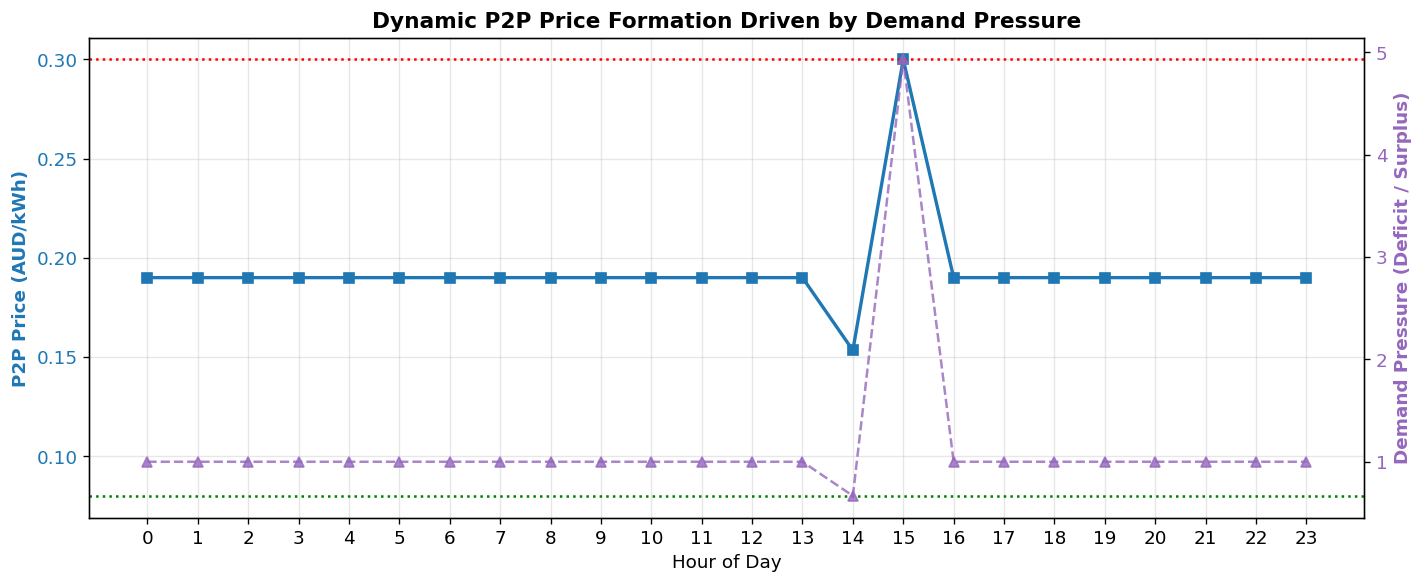

In [16]:
# ── PLOT 4: Dynamic P2P Pricing vs Demand Pressure ─────────────────────────
p2p_prices = [r.equilibrium_p2p_price_aud or r.p2p_price_aud for r in hourly_results]
demand_pressures = [r.equilibrium_demand_pressure if r.equilibrium_demand_pressure is not None else 1.0 for r in hourly_results]

fig, ax1 = plt.subplots(figsize=(12, 5))

color1 = 'tab:blue'
ax1.set_xlabel('Hour of Day')
ax1.set_ylabel('P2P Price (AUD/kWh)', color=color1, fontweight='bold')
l1 = ax1.plot(hours, p2p_prices, color=color1, marker='s', linewidth=2, label='Dynamic P2P Price')
ax1.axhline(GRID_IMPORT_PRICE, color='red', linestyle=':', label=f'Grid Retail (${GRID_IMPORT_PRICE:.2f})')
ax1.axhline(GRID_EXPORT_CREDIT, color='green', linestyle=':', label=f'Feed-in Tariff (${GRID_EXPORT_CREDIT:.2f})')
ax1.tick_params(axis='y', labelcolor=color1)
ax1.set_xticks(hours)
ax1.grid(True, alpha=0.3)

ax2 = ax1.twinx()
color2 = 'tab:purple'
ax2.set_ylabel('Demand Pressure (Deficit / Surplus)', color=color2, fontweight='bold')
l2 = ax2.plot(hours, demand_pressures, color=color2, linestyle='--', marker='^', alpha=0.8, label='Demand Pressure')
ax2.tick_params(axis='y', labelcolor=color2)

plt.title('Dynamic P2P Price Formation Driven by Demand Pressure', fontweight='bold')
fig.tight_layout()
plt.savefig(os.path.join(fig_dir, '05_dynamic_pricing_curve.png'), bbox_inches='tight')
plt.show()

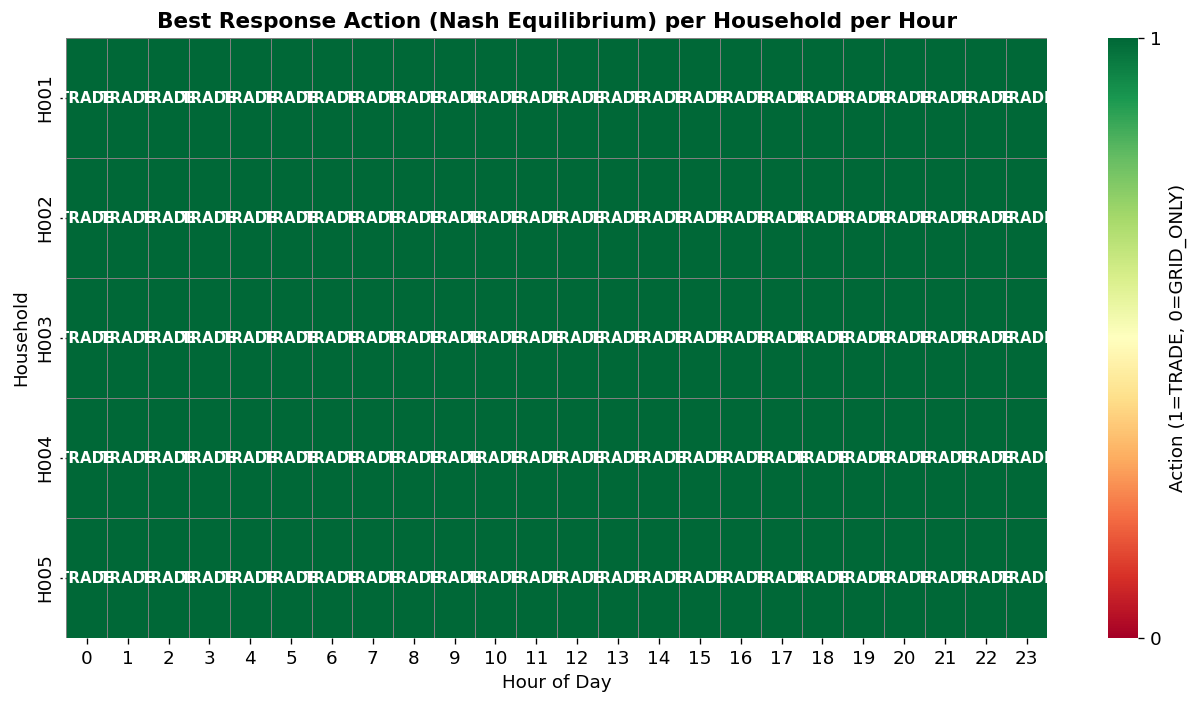

In [20]:
# ── PLOT 5: Best Response Heatmap ──────────────────────────────────────────
br_num = df_br_pivot.replace({'TRADE': 1, 'GRID_ONLY': 0})

plt.figure(figsize=(11, 6))
sns.heatmap(
    br_num.T.astype(float),
    cmap='RdYlGn',
    vmin=0, vmax=1,
    linewidths=0.5,
    linecolor='grey',
    cbar_kws={'label': 'Action (1=TRADE, 0=GRID_ONLY)', 'ticks': [0, 1]},
    annot=df_br_pivot.T.values,
    fmt='',
    annot_kws={'size': 9, 'weight': 'bold'},
)
plt.title('Best Response Action (Nash Equilibrium) per Household per Hour', fontweight='bold')
plt.xlabel('Hour of Day')
plt.ylabel('Household')
plt.tight_layout()
plt.savefig(os.path.join(fig_dir, '05_best_response_heatmap_battery.png'), bbox_inches='tight')
plt.show()

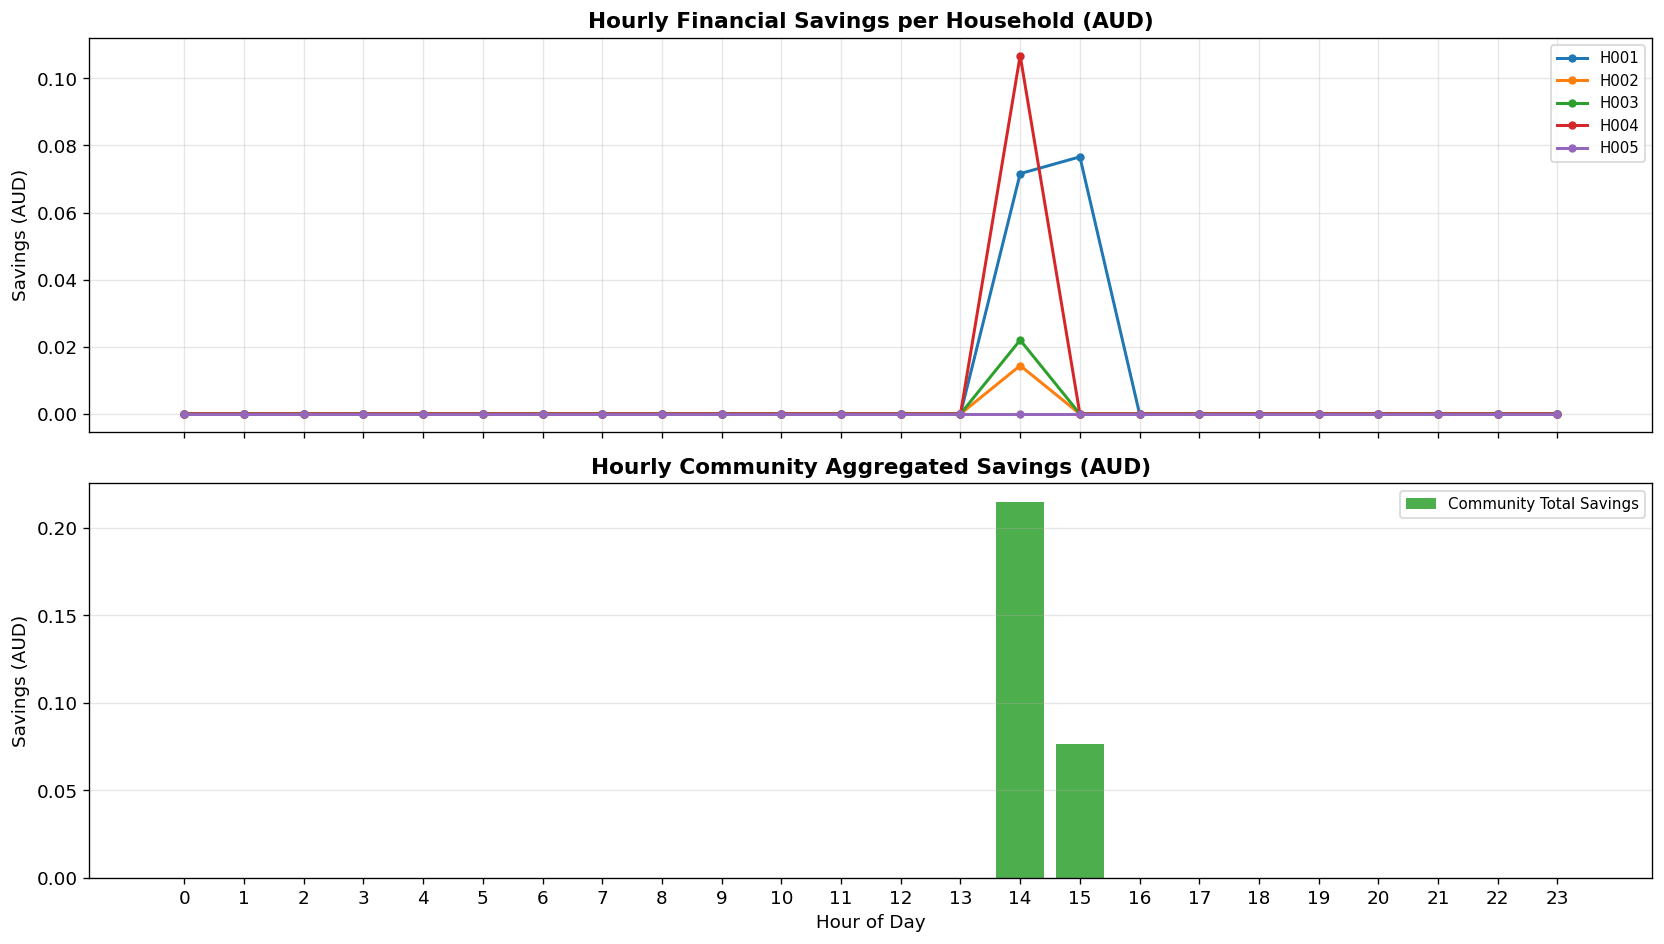

In [21]:
# ── PLOT 6: Hourly Savings per Household & Community Total ─────────────────
df_savings = df_ops.pivot(index='Hour', columns='Player', values='Saving_AUD')
df_savings['Community'] = df_savings.sum(axis=1)

fig, axes = plt.subplots(2, 1, figsize=(14, 8), sharex=True)

for i, pid in enumerate(PLAYER_IDS):
    axes[0].plot(hours, df_savings[pid], marker='o', markersize=4, label=pid, color=colors[i], linewidth=1.8)
axes[0].set_title('Hourly Financial Savings per Household (AUD)', fontweight='bold')
axes[0].set_ylabel('Savings (AUD)')
axes[0].legend(loc='upper right')
axes[0].grid(True, alpha=0.3)

axes[1].bar(hours, df_savings['Community'], color='#2ca02c', alpha=0.85, label='Community Total Savings')
axes[1].set_title('Hourly Community Aggregated Savings (AUD)', fontweight='bold')
axes[1].set_xlabel('Hour of Day')
axes[1].set_ylabel('Savings (AUD)')
axes[1].set_xticks(hours)
axes[1].legend(loc='upper right')
axes[1].grid(True, alpha=0.3, axis='y')

plt.tight_layout()
plt.savefig(os.path.join(fig_dir, '05_hourly_savings_battery.png'), bbox_inches='tight')
plt.show()

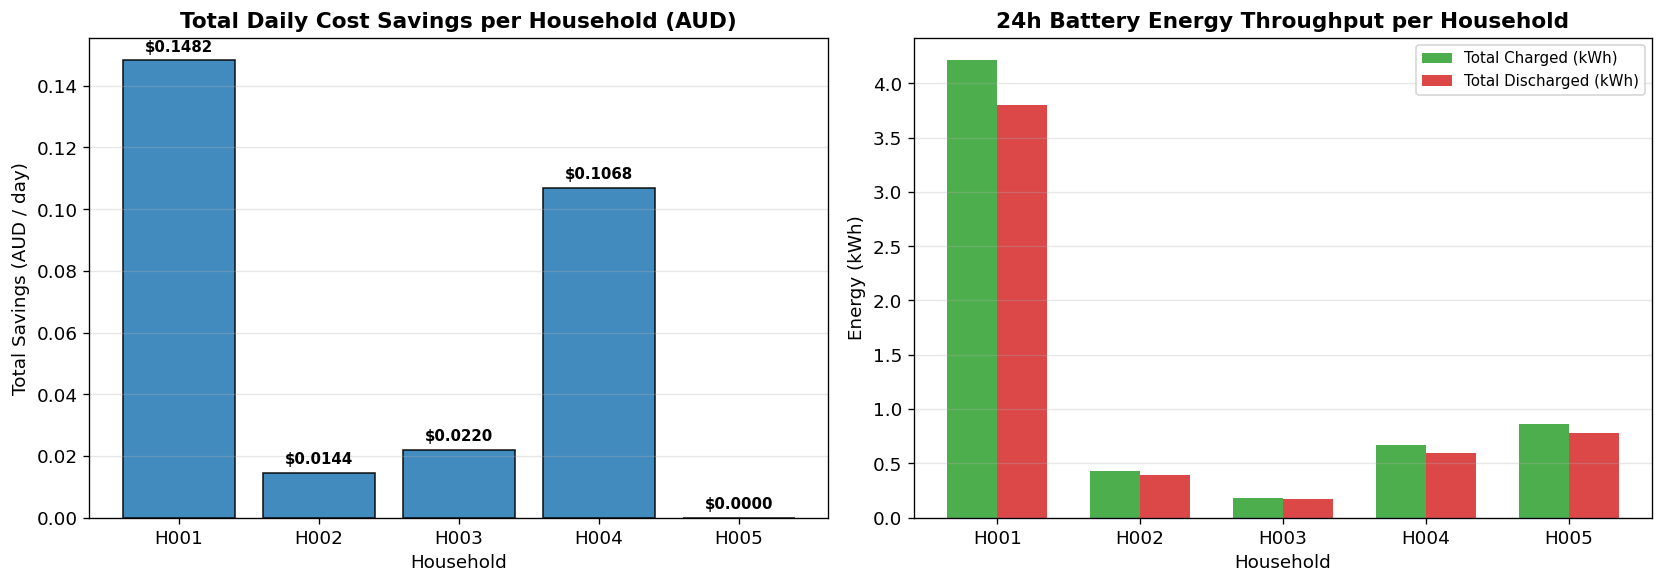

In [22]:
# ── PLOT 7: Total Daily Benefit & Battery Cycling ──────────────────────────
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Left: Savings per house
savings_vals = df_summary['Total_Saving_AUD'].values
bars = axes[0].bar(PLAYER_IDS, savings_vals, color='#1f77b4', alpha=0.85, edgecolor='black')
axes[0].set_title('Total Daily Cost Savings per Household (AUD)', fontweight='bold')
axes[0].set_ylabel('Total Savings (AUD / day)')
axes[0].set_xlabel('Household')
axes[0].grid(True, alpha=0.3, axis='y')
for b, val in zip(bars, savings_vals):
    axes[0].text(b.get_x() + b.get_width()/2, b.get_height() + 0.002, f'${val:.4f}', ha='center', va='bottom', fontweight='bold', fontsize=9)

# Right: Battery throughput (charged vs discharged)
x = np.arange(len(PLAYER_IDS))
w = 0.35
axes[1].bar(x - w/2, df_summary['Batt_Total_Charged_kWh'], width=w, label='Total Charged (kWh)', color='#2ca02c', alpha=0.85)
axes[1].bar(x + w/2, df_summary['Batt_Total_Discharged_kWh'], width=w, label='Total Discharged (kWh)', color='#d62728', alpha=0.85)
axes[1].set_xticks(x)
axes[1].set_xticklabels(PLAYER_IDS)
axes[1].set_title('24h Battery Energy Throughput per Household', fontweight='bold')
axes[1].set_ylabel('Energy (kWh)')
axes[1].set_xlabel('Household')
axes[1].legend()
axes[1].grid(True, alpha=0.3, axis='y')

plt.tight_layout()
plt.savefig(os.path.join(fig_dir, '05_daily_benefit_and_battery_throughput.png'), bbox_inches='tight')
plt.show()

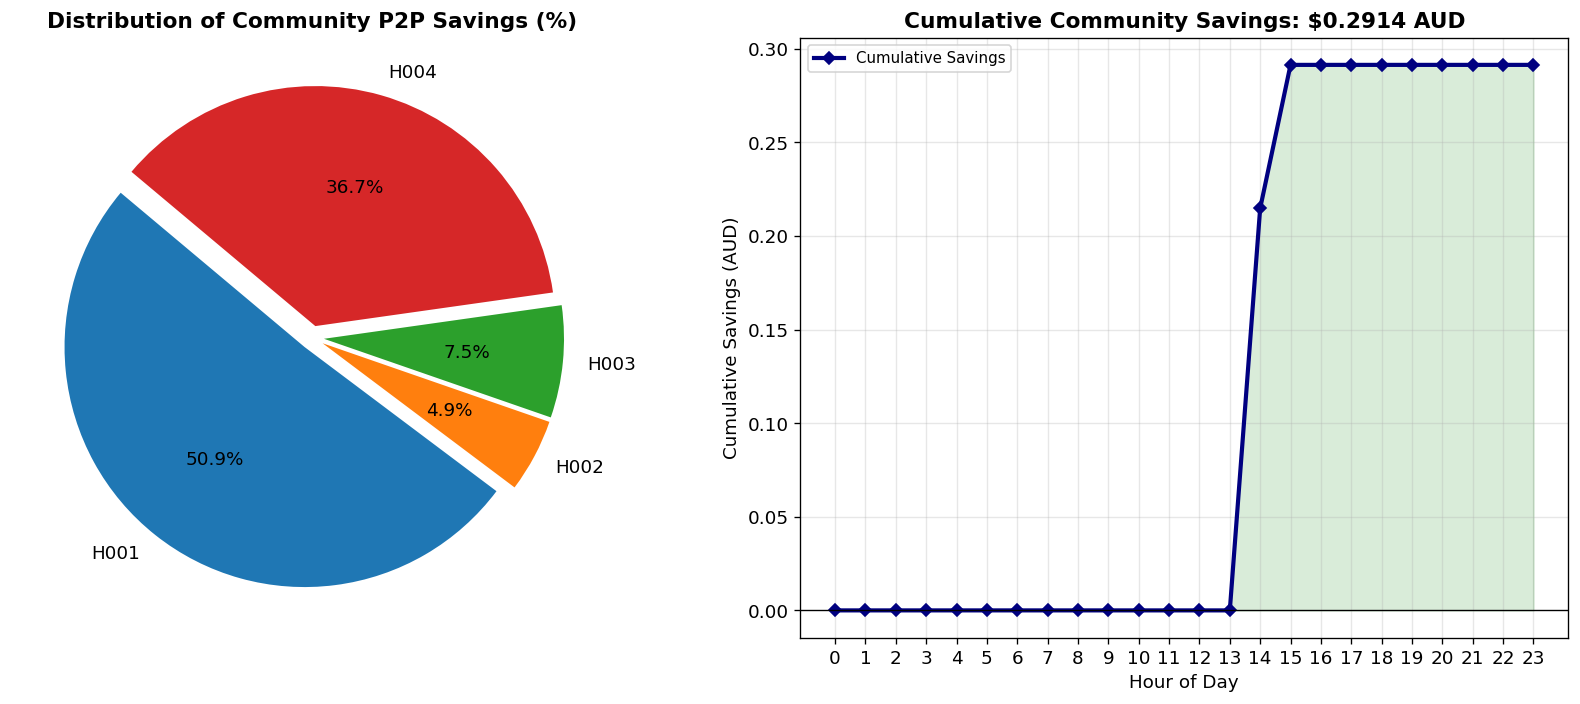

In [23]:
# ── PLOT 8: Savings Share Pie Chart & Cumulative Welfare Gain ──────────────
fig, axes = plt.subplots(1, 2, figsize=(14, 6))

# Left: Savings breakdown pie
pos_mask = savings_vals > 0
if pos_mask.any():
    axes[0].pie(
        savings_vals[pos_mask],
        labels=[PLAYER_IDS[i] for i in range(len(PLAYER_IDS)) if pos_mask[i]],
        autopct='%1.1f%%',
        colors=[colors[i] for i in range(len(PLAYER_IDS)) if pos_mask[i]],
        startangle=140,
        explode=[0.05]*sum(pos_mask),
    )
    axes[0].set_title('Distribution of Community P2P Savings (%)', fontweight='bold')
else:
    axes[0].text(0.5, 0.5, 'No positive savings recorded', ha='center', va='center')

# Right: Cumulative community savings over the day
cum_savings = np.cumsum(df_savings['Community'].values)
axes[1].plot(hours, cum_savings, color='navy', marker='D', markersize=5, linewidth=2.5, label='Cumulative Savings')
axes[1].fill_between(hours, 0, cum_savings, color='green', alpha=0.15)
axes[1].axhline(0, color='black', linewidth=0.8)
axes[1].set_title(f'Cumulative Community Savings: ${comm_savings:.4f} AUD', fontweight='bold')
axes[1].set_xlabel('Hour of Day')
axes[1].set_ylabel('Cumulative Savings (AUD)')
axes[1].set_xticks(hours)
axes[1].grid(True, alpha=0.3)
axes[1].legend()

plt.tight_layout()
plt.savefig(os.path.join(fig_dir, '05_cumulative_welfare_gain.png'), bbox_inches='tight')
plt.show()

## 7. Conclusions & Findings

1. **Battery Integration Impact**:
   - Batteries act as the first line of defense: each household stores its own excess solar generation during midday hours ($10:00 - 15:00$) and draws upon stored energy during morning and evening peaks.
   - This substantially flattens the peak net demand and peak net export, reducing grid stress.
2. **Dynamic P2P Market Participation**:
   - When batteries reach their maximum SOC ($90%$) or cannot absorb more power, surplus energy spills over into the P2P pool.
   - When batteries hit their minimum SOC ($10%$) or cannot discharge more power, remaining unmet deficit is purchased from peers in the P2P pool before turning to the main grid.
3. **Dynamic Demand-Responsive Pricing**:
   - The P2P trading price automatically fluctuates between the feed-in tariff ($0.08/kWh) and grid retail tariff ($0.30/kWh) based on the instantaneous ratio of pool deficit to surplus.
4. **Financial Win-Win**:
   - Every participating household achieves non-negative cost savings compared to the uncoordinated grid-only baseline.
   - The total community savings over the 24-hour cycle demonstrate the effectiveness of combining behind-the-meter battery storage with game-theoretic peer-to-peer trading.